# Plot the time series of each simulation 

In [1]:
import numpy as np
import os
import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

import h5py
import json

from field_config import field_labels, field_lims, field_scales

In [2]:
bowshock_config_dict = json.load(open("../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd_revised"

### Plotting shock parameter in each row, model in each column

The angular dependence is plotted using a cmap color scheme following the bow shock colors

In [3]:
params = ["encr", "geff", "shma", 'alpha_inj', 'crac']
# params = ["dens", "pres", "vel", "mag"]
# params = ["shma", "crac"]

# params = ["mgob", "crac"]
bs_names = list(bowshock_config.keys())
bs_names.remove("ISM-v40-MHD")

bs_names = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]
# bs_names.remove("ISM-v100")
shock_type = "term"

# create a custom qualitative cmap based on the average quantity of the theta range
theta_ranges_plot = np.arange(0, 180+45, 45)
theta_cmap = cm.viridis
theta_norm = mcolors.Normalize(vmin=0, vmax=180, clip=False)

theta_ranges_color = [theta_cmap(theta_norm(th)) for th in theta_ranges_plot]

theta_ranges_cmap = mcolors.LinearSegmentedColormap.from_list('theta_cmap', theta_ranges_color, len(theta_ranges_color))
theta_ranges_norm = mcolors.BoundaryNorm(theta_ranges_plot, theta_ranges_cmap.N)

In [4]:
param_textpos = {"encr": 2.5e-12, "shma": 25, "crac": 0.15, "geff": 1.65, "alpha_inj":4.0, "mgob": 0.5, 'einj':5e-14}

In [5]:
# param_textpos = {"dens" : 27, "vel" : 1e3, "pres" : 5e4, "mag" : 1e-5}

# field_lims = {
#     "dens" : (0.05, 1),
#     "pres" : (2e3, 7e5),
#     "mag" : (0.1, 20),
#     "vel" : (1, 200),
# }

# field_scales = {
#     "dens" : "linear",
#     "pres" : "log",
#     "mag" : "linear",
#     "vel" : "linear"
# }

# field_labels = {
#     "dens" : r"$\rho$ / 10$^{-24}$ g cm$^{-3}$",
#     "pres" : r"(P / $k_B$) / K cm$^{-3}$",
#     "mag" : r"$|\vec{B}|$ / 10$^{-6}$ G",
#     "vel" : r"$|\vec{v}|$ / km s${-1}$",
# }

<KeysViewHDF5 ['ISM-v100-MDiff', 'ISM-v40-HDiff', 'ISM-v40-LDiff', 'ISM-v40-MDiff', 'ISM-v40-MHD']>
Processing ISM-v40-MDiff for parameter encr...
Processing ISM-v40-LDiff for parameter encr...
Processing ISM-v40-HDiff for parameter encr...
Processing ISM-v100-MDiff for parameter encr...
<KeysViewHDF5 ['ISM-v100-MDiff', 'ISM-v40-HDiff', 'ISM-v40-LDiff', 'ISM-v40-MDiff', 'ISM-v40-MHD']>
Processing ISM-v40-MDiff for parameter geff...
Processing ISM-v40-LDiff for parameter geff...
Processing ISM-v40-HDiff for parameter geff...
Processing ISM-v100-MDiff for parameter geff...
<KeysViewHDF5 ['ISM-v100-MDiff', 'ISM-v40-HDiff', 'ISM-v40-LDiff', 'ISM-v40-MDiff', 'ISM-v40-MHD']>
Processing ISM-v40-MDiff for parameter shma...
Processing ISM-v40-LDiff for parameter shma...
Processing ISM-v40-HDiff for parameter shma...
Processing ISM-v100-MDiff for parameter shma...
<KeysViewHDF5 ['ISM-v100-MDiff', 'ISM-v40-HDiff', 'ISM-v40-LDiff', 'ISM-v40-MDiff', 'ISM-v40-MHD']>
Processing ISM-v40-MDiff for para

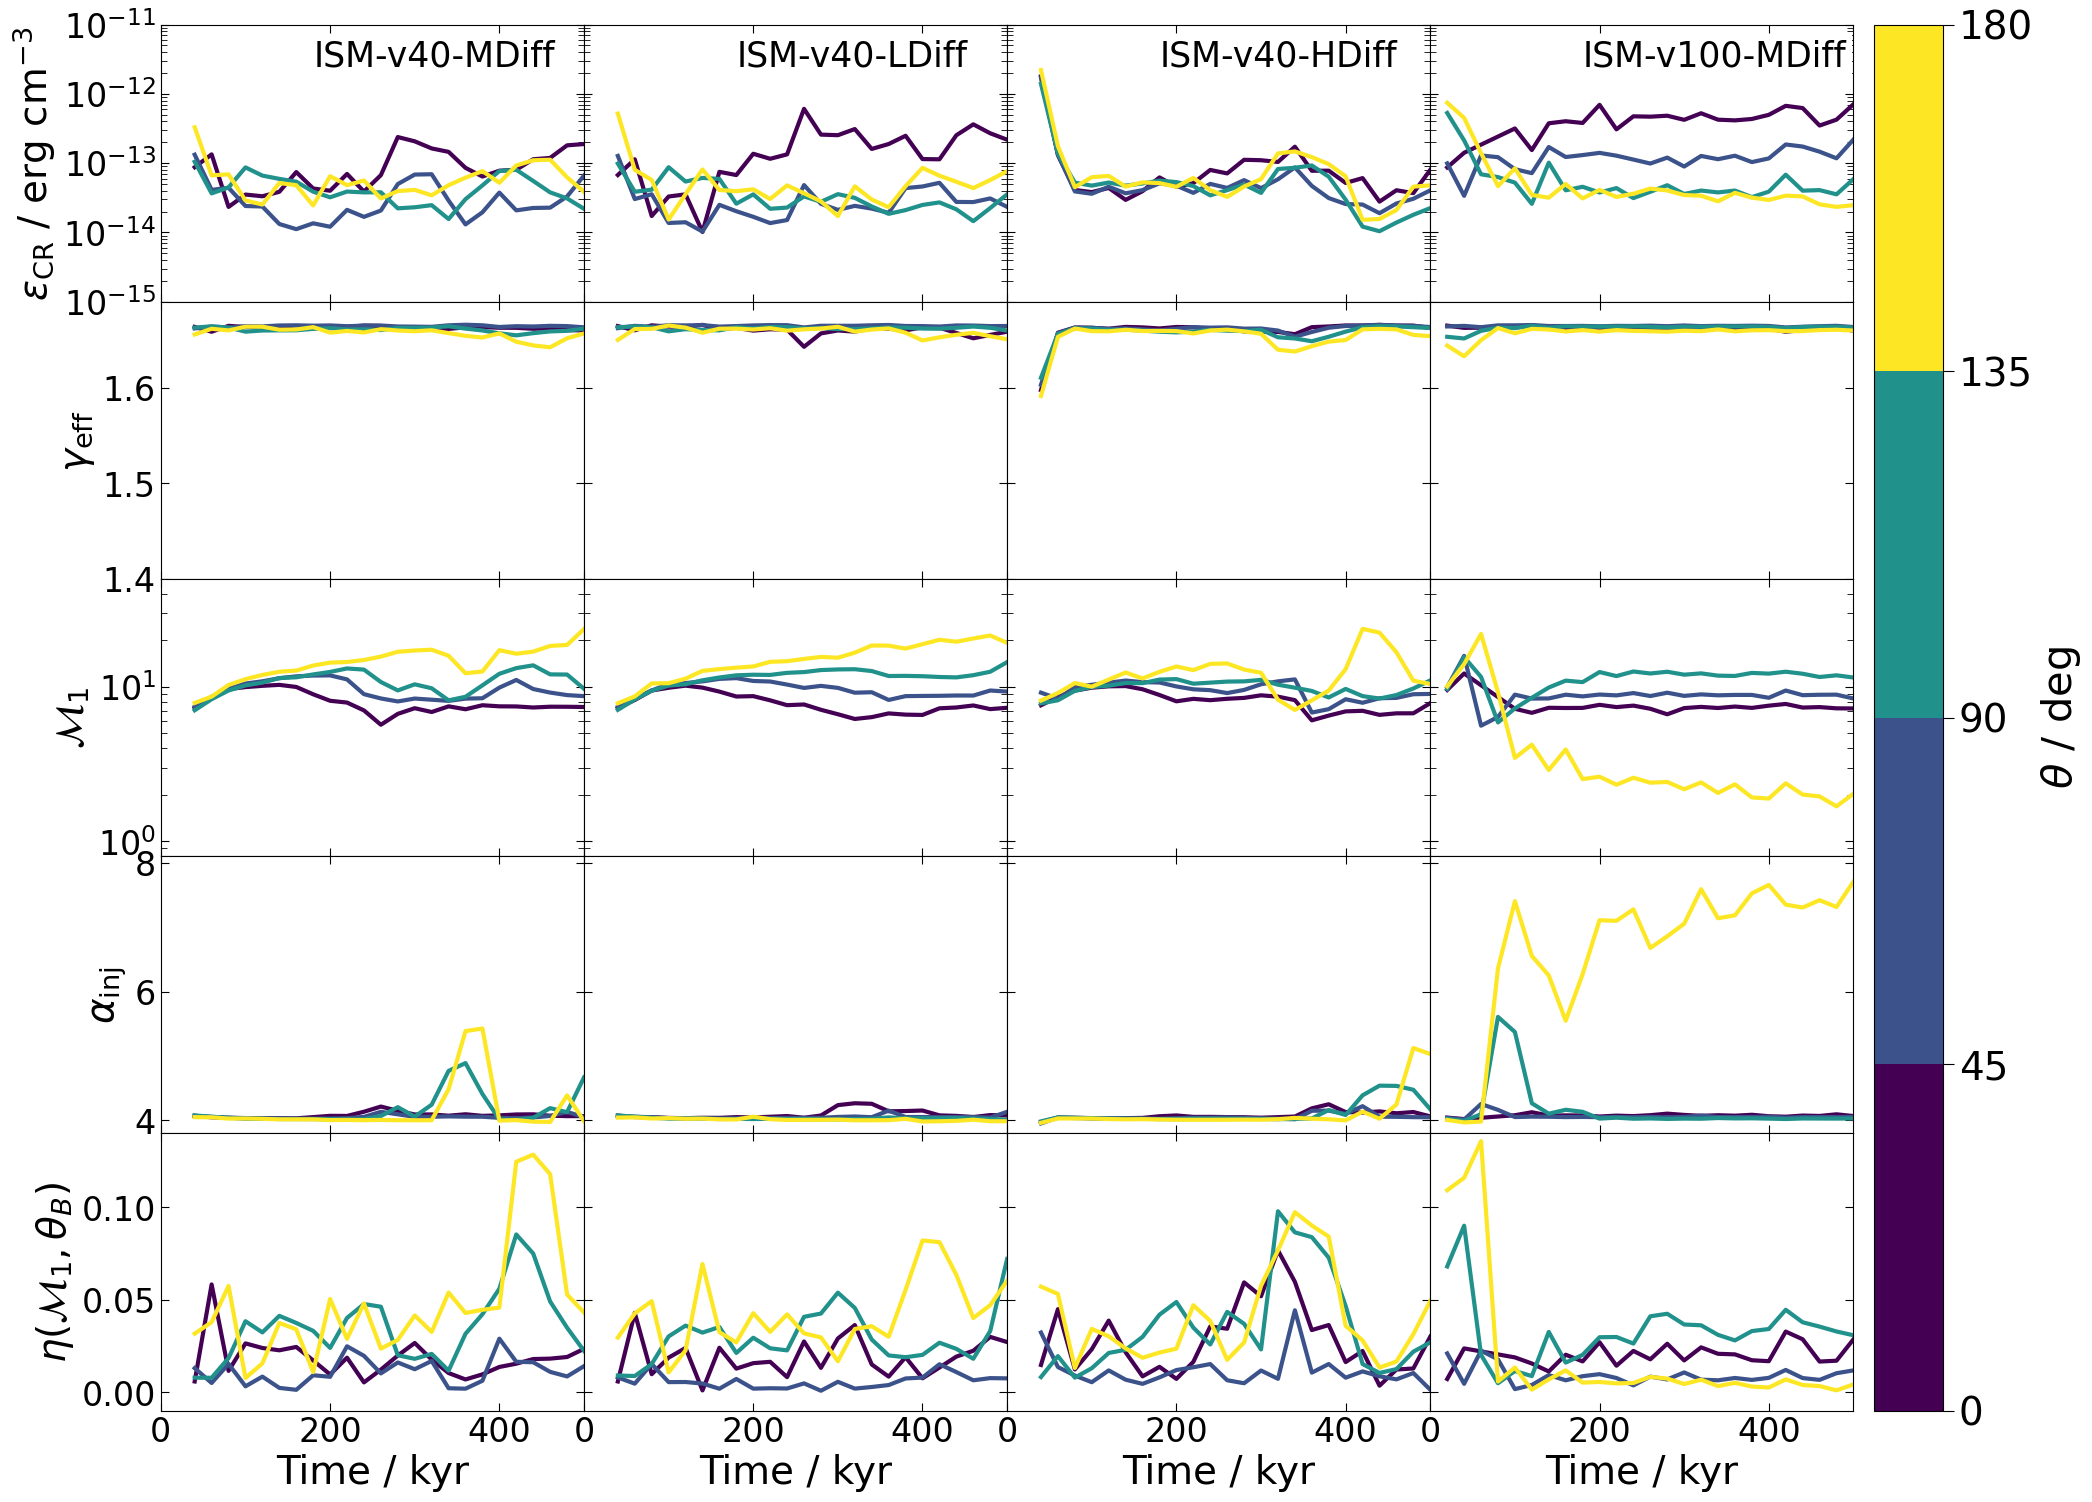

In [6]:
fig = plt.figure(figsize=(26, 18))
# fig = plt.figure(figsize=(26, 10))
gs = fig.add_gridspec(len(params), len(bs_names), hspace=0, wspace=0)
axs = gs.subplots(sharex=True, sharey=False)

for ip, p in enumerate(params):
    file_to_read = f"../data/polar_time_series_{shock_type}_revised.h5"
    with h5py.File(file_to_read, "r") as f:

        print(f.keys())
        
        for ibs, bs_name in enumerate(bs_names):
            print(f"Processing {bs_name} for parameter {p}...")
        # bs_labels = ['Before Rescaling', 'After Rescaling']
        # for ibs, bs_name in enumerate(['BowShock_CR_old', 'BowShock_CR_new']):
            # if bs_name in set(["ISM-v60"]):
            #     continue
            
            theta_range_sims = f[bs_name]["theta_ranges"][()]
            theta_minval_sims = [th_sim[0] for th_sim in theta_range_sims]
            theta_maxval_sims = [th_sim[1] for th_sim in theta_range_sims]

            param_arr = f[bs_name][p][()]

            # if p == "vel":
            #     param_arr *= 1e-5
            # if p == "mag":
            #     param_arr *= 1e6
            if p == "mag":
                param_arr *= 1e6
            if p == "dens":
                param_arr *= 1e24

            for itr, theta_maxval in enumerate(theta_ranges_plot[1:]):
                times = (f[bs_name]["times"][()] * u.s).to(u.kyr)
                theta_minval_idx = np.digitize(theta_ranges_plot[itr], theta_minval_sims, right=True)
                theta_maxval_idx = np.digitize(theta_maxval, theta_maxval_sims, right=True)
                # remove nans
                
                param_val_theta = np.mean(param_arr[:, theta_minval_idx:theta_maxval_idx+1], axis=-1)
                times = times[~np.isnan(param_val_theta)]
                param_val_theta = param_val_theta[~np.isnan(param_val_theta)]
                # param_val_theta = np.mean(np.where(np.isnan(param_val_theta), 0.0, param_val_theta), axis=-1)

                theta_mean = 0.5 * (theta_ranges_plot[itr] + theta_maxval)

                # now just sort in increasing time
                sorted_indces = np.argsort(times)
                times = times[sorted_indces]
                param_val_theta = param_val_theta[sorted_indces]

                pl = axs[ip, ibs].plot(
                    times,
                    param_val_theta,
                    color=theta_ranges_cmap(theta_ranges_norm(theta_mean)),
                    lw=3.0,
                )

            # labels
            axs[ip, ibs].set_xlabel("Time / kyr", fontsize=28)
            if ibs == 0:
                axs[ip, ibs].set_ylabel(field_labels[p], fontsize=28)

            # limits
            axs[ip, ibs].set_xlim([0, 500])
            axs[ip, ibs].set_ylim(field_lims[p])

            # scales
            axs[ip, ibs].set_yscale(field_scales[p])

            # ticks
            axs[ip, ibs].tick_params(
                axis="x", direction="in", which="major", size=6, labelsize=24, top=True
            )
            axs[ip, ibs].tick_params(
                axis="x", direction="in", which="minor", size=4, labelsize=20, top=True
            )
            axs[ip, ibs].tick_params(
                axis="y",
                direction="in",
                which="major",
                size=6,
                labelsize=24,
                right=True
            )
            axs[ip, ibs].tick_params(
                axis="y",
                direction="in",
                which="minor",
                size=4,
                labelsize=20,
                right=True
            )

            if ibs != 0:
                axs[ip, ibs].yaxis.set_ticklabels([])

            if ip == 0:
                axs[ip, ibs].annotate(
                    # f"{bowshock_config[bs_name]['label']}",
                    f"{bs_name}",
                    xy=(180, param_textpos[p]),
                    fontsize=25,
                    bbox=dict(facecolor="white", edgecolor="none"),
                )

# colorbar
sm = cm.ScalarMappable(cmap=theta_ranges_cmap, norm=theta_ranges_norm)
cbar = fig.colorbar(sm, ax=axs.ravel().tolist(), pad=0.01)
cbar.ax.set_ylabel(r"$\theta$ / deg", fontsize=30)
cbar.ax.tick_params(axis="both", which="major", size=8, labelsize=28)
cbar.ax.tick_params(axis="both", which="minor", size=6, labelsize=28)

# fig.savefig(
#     os.path.join(fig_dir, f"timeseries_{shock_type}.pdf"),
#     dpi=200,
#     bbox_inches="tight",
# )
# fig.savefig(
#     os.path.join(fig_dir, f"timeseries_{shock_type}_simpler.pdf"),
#     dpi=200,
#     bbox_inches="tight",
# )